# 03 · Retention economics: who gets an offer, and does it pay?

**Summary.** The report's retention economics reproduce exactly. Ranking by revenue at risk puts 58.0% of churned revenue in the
top 30% of offers, against 44.1% when ranking by churn risk. At the simulator's defaults ($25 offer, 20% save rate, 12
months of revenue), offering the top 30% nets **$234K on the 15,315 hold-out subscribers (ROI 204%)**. The best share
is 60% ($276K), 55% more than ranking by risk. Those dollars are true for the modelling sample, where 28.8% of
subscribers churn, and **not for a real base**. Reweighted to an assumed 2% monthly churn rate, the same campaign
*loses* $80K: even in the top decile by revenue at risk only 3.2% churn, so an offer must cost under about $9 to pay
back. The ranking advice survives the correction; the budget advice does not. Offering only where the prior-corrected
expected value is positive fixes the policy. With a $5 offer that is 15% of the base and nets $6.2K per 15,315
subscribers, and the backtest matches the model's own expectation ($6.5K), which validates the correction. The answer
still rests on a save rate nobody has measured: across 2,000 Monte Carlo draws of save rate, churn rate, months kept and
margin, even the $5 offer to the top 10% loses money 38% of the time. **Recommendation:** keep the value ranking, cap
offers at single-digit dollars, use expected-value targeting, and run an 80/20 randomised hold-out on the top 10%
(about 10,700 subscribers per arm at 50/50 to detect a 20% save rate) before scaling anything.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

In [2]:
import time
from threadpoolctl import threadpool_limits
from sklearn.ensemble import HistGradientBoostingClassifier
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
threadpool_limits(4)
plt.rcParams["text.parse_math"] = False      # titles carry dollar amounts; this notebook draws no math text
usd_k = lambda v: f"{'-' if v < 0 else ''}${abs(v) / 1e3:,.1f}K"
T0 = time.perf_counter()

## 1. The value equation

A retention offer to subscriber *i* is worth making when its expected value is positive:

**EV = P(churn) x save rate x months kept x monthly revenue x margin - offer cost**

The Power BI simulator runs this as a backtest on the 15,315 hold-out subscribers, with four inputs. Its defaults:

| Input | Default | Status |
|---|---|---|
| Ranking | By revenue at risk (P(churn) x monthly revenue) | A choice |
| Share offered | Top 30% | A choice |
| Offer cost | $25 per subscriber offered | Assumption |
| Save rate | 20% of would-be churners kept | Assumption: **no randomised test exists** |
| Months kept, margin | 12 months of revenue (margin not applied) | Assumption |

Rebuild the hold-out exactly as the ETL does: the champion's rounded score, risk deciles and revenue-at-risk deciles.

In [3]:
d = F.load()
y = d["Churned"].values
X = F.etl_matrix(d)
tr, te = F.split(d)
champion = HistGradientBoostingClassifier(**F.GBM_PARAMS).fit(X.iloc[tr], y[tr])
test = d.iloc[te][["Churned", "MonthlyRevenue"]].reset_index(drop=True)
test["ChurnScore"] = np.round(champion.predict_proba(X.iloc[te])[:, 1], 4)
test["RiskDecile"] = F.deciles(test["ChurnScore"])
test["ValueAtRisk"] = test["ChurnScore"] * test["MonthlyRevenue"].fillna(0)
test["ValueDecile"] = F.deciles(test["ValueAtRisk"])
pub = pd.read_csv(ROOT / "data" / "model_metrics.csv").set_index("Metric")["Value"]
rev = test["MonthlyRevenue"].fillna(0) * test["Churned"]
cap = {"revenue_top_30_capture_by_value": rev[test["ValueDecile"] <= 3].sum() / rev.sum(),
       "revenue_top_30_capture_by_risk": rev[test["RiskDecile"] <= 3].sum() / rev.sum()}
parity = pd.DataFrame({"published": pub[list(cap)], "reproduced": pd.Series(cap)})
assert (parity["published"] - parity["reproduced"]).abs().max() <= 0.005
print(f"{len(test):,} hold-out subscribers, churn {test['Churned'].mean():.1%}, mean monthly revenue ${test['MonthlyRevenue'].mean():.2f}")
parity

15,315 hold-out subscribers, churn 28.8%, mean monthly revenue $58.26


,published,reproduced
revenue_top_30_capture_by_value,0.5796,0.5796
revenue_top_30_capture_by_risk,0.4410,0.4410


## 2. Rank by revenue at risk, not by risk

The published comparison reproduces: the top 30% by revenue at risk hold 58.0% of the monthly revenue that churned,
against 44.1% for the top 30% by churn risk. The cumulative view shows the whole trade-off, with a ranking by revenue
alone and a random list for reference.

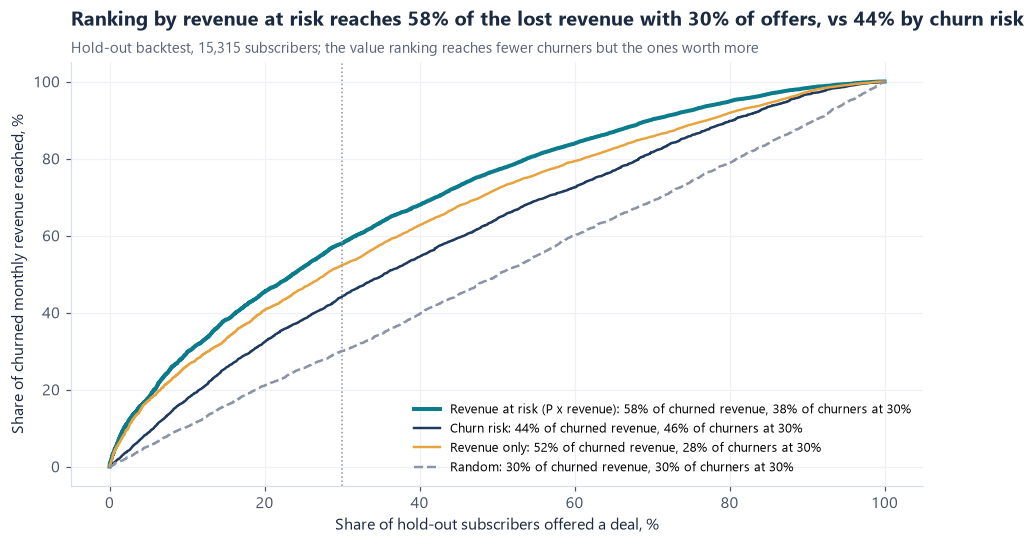

,churned_revenue_captured_top30,churners_captured_top30
Revenue at risk (P x revenue),0.5795,0.3752
Churn risk,0.4413,0.4590
Revenue only,0.5231,0.2843
Random,0.2999,0.2997


In [4]:
def capture_curve(score):
    o = np.argsort(-np.asarray(score), kind="stable")
    return np.r_[0, np.cumsum(rev.values[o])] / rev.sum(), np.r_[0, np.cumsum(test["Churned"].values[o])] / test["Churned"].sum()


rankings = {"Revenue at risk (P x revenue)": test["ValueAtRisk"], "Churn risk": test["ChurnScore"], "Revenue only": test["MonthlyRevenue"].fillna(0),
            "Random": np.random.default_rng(SEED).random(len(test))}
share = np.arange(len(test) + 1) / len(test)
curves = {k: capture_curve(s) for k, s in rankings.items()}
k30 = int(round(0.3 * len(test)))
cmp_ = pd.DataFrame({k: {"churned_revenue_captured_top30": c[0][k30], "churners_captured_top30": c[1][k30]} for k, c in curves.items()}).T
fig, ax = plt.subplots(figsize=(10, 5))
for (k, c), col in zip(curves.items(), (PALETTE["teal"], PALETTE["navy"], PALETTE["amber"], PALETTE["grey"])):
    ax.plot(share * 100, c[0] * 100, color=col, lw=2.6 if "at risk" in k else 1.6, ls="--" if k == "Random" else "-",
            label=f"{k}: {c[0][k30]:.0%} of churned revenue, {c[1][k30]:.0%} of churners at 30%")
ax.axvline(30, color=PALETTE["grey"], ls=":", lw=1)
ax.set_xlabel("Share of hold-out subscribers offered a deal, %"); ax.set_ylabel("Share of churned monthly revenue reached, %")
ax.legend(loc="lower right", fontsize=8.5)
headline(ax, "Ranking by revenue at risk reaches 58% of the lost revenue with 30% of offers, vs 44% by churn risk",
         "Hold-out backtest, 15,315 subscribers; the value ranking reaches fewer churners but the ones worth more")
savefig(fig, "03-value-vs-risk", FIG); plt.show()
cmp_

## 3. The simulator, reproduced

Net value = 12 months of revenue from saved churners - offer spend, at the defaults ($25 offer, 20% save rate), for
every share and both rankings.

In [5]:
DEF = dict(offer_cost=25.0, save_rate=0.2, months=12)
RANKS = {"value": "ValueDecile", "risk": "RiskDecile"}
sim = pd.DataFrame([{"ranking": r, "share": k, **F.simulate(test, col, k, **DEF)} for r, col in RANKS.items() for k in range(10, 101, 10)])
sv = sim[sim["ranking"] == "value"].set_index("share")
sr = sim[sim["ranking"] == "risk"].set_index("share")
published = {"net value at 30%, value ranking": (234_225, sv.loc[30, "net"]), "ROI at 30%": (2.04, sv.loc[30, "roi"]),
             "best share, value ranking": (60, sv["net"].idxmax()), "value vs risk ranking at 30%": (1.55, sv.loc[30, "net"] / sr.loc[30, "net"])}
pubt = pd.DataFrame(published, index=["README / report", "reproduced"]).T
assert abs(sv.loc[30, "net"] - 234_225) < 1 and abs(sv.loc[30, "roi"] - 2.04) < 0.005 and sv["net"].idxmax() == 60
print(pubt.to_string())
sim.pivot(index="share", columns="ranking", values=["net", "roi"])

                                 README / report   reproduced
net value at 30%, value ranking     234,225.0000 234,225.3040
ROI at 30%                                2.0400       2.0390
best share, value ranking                60.0000      60.0000
value vs risk ranking at 30%              1.5500       1.5541


net                 roi       
ranking         risk        value   risk  value
share                                          
10       67,339.5760 140,585.8240 1.7582 3.6706
20      118,163.1600 196,956.6480 1.5431 2.5721
30      150,718.9360 234,225.3040 1.3120 2.0390
40      175,162.0320 255,985.0320 1.1437 1.6715
50      195,865.0880 272,192.9600 1.0232 1.4219
60      206,830.1040 275,581.4640 0.9003 1.1996
70      223,549.7840 274,696.3280 0.8341 1.0250
80      234,175.8720 264,958.6320 0.7645 0.8650
90      237,604.8800 247,526.6000 0.6896 0.7184
100     219,435.5520 219,435.5520 0.5731 0.5731

The report's numbers come from this backtest: **$234K net at the default 30% (ROI 204%), the best share at 60% ($276K),
and 55% more than ranking by risk ($151K)**. They are correct arithmetic on the hold-out, but they inherit its churn
mix. 28.8% of the hold-out churned, so every offer finds a would-be churner 29% of the time. On a real base churning
at about 2% a month, it finds one about 2-4% of the time even at the top of the list.

## 4. The same campaign on a realistic base

Reweight the hold-out so it churns at the assumed 2% a month: each churner counts 0.069 and each stayer 1.377, the same
head count in total. The ranking is unchanged; only the mix of the people each offer reaches changes.

In [6]:
w = F.population_weights(test["Churned"].values)
sim_pop = pd.DataFrame([{"ranking": r, "share": k, **F.simulate(test, col, k, weights=w, **DEF)} for r, col in RANKS.items() for k in range(10, 101, 10)])
free = pd.DataFrame([{"ranking": r, "share": k, **F.simulate(test, col, k, weights=w, offer_cost=0.0, save_rate=0.2, months=12)}
                     for r, col in RANKS.items() for k in range(10, 101, 10)])
free["break_even_cost"] = free["retained"] / free["targeted"]
free["churn_rate_reached"] = free["churners_reached"] / free["targeted"]
by = lambda t, r, c: t[t["ranking"] == r].set_index("share")[c]
pop = pd.DataFrame({"net_value": by(sim_pop, "value", "net"), "net_risk": by(sim_pop, "risk", "net"),
                    "break_even_cost_value": by(free, "value", "break_even_cost"), "break_even_cost_risk": by(free, "risk", "break_even_cost"),
                    "real_churn_reached_value": by(free, "value", "churn_rate_reached"), "real_churn_reached_risk": by(free, "risk", "churn_rate_reached")})
pop

,net_value,net_risk,break_even_cost_value,break_even_cost_risk,real_churn_reached_value,real_churn_reached_risk
share,,,,,,
10,"-20,477.3796","-18,435.0921",9.4356,7.1130,0.0320,0.0555
20,"-49,348.3848","-43,572.7607",6.9450,5.9182,0.0288,0.0449
30,"-79,773.8030","-73,540.7982",5.8236,5.0100,0.0276,0.0382
40,"-112,517.5079","-105,575.3294",5.0373,4.4375,0.0263,0.0341
50,"-145,581.1172","-139,536.3340",4.5250,4.0376,0.0256,0.0310
60,"-181,299.3297","-176,395.6936",4.0517,3.6643,0.0245,0.0281
70,"-217,379.4865","-213,149.8649",3.6917,3.4490,0.0237,0.0261
80,"-256,590.7132","-252,418.7406",3.3456,3.2342,0.0225,0.0241
90,"-298,362.3602","-294,769.1718",3.0262,3.0135,0.0211,0.0221


On a 2% base, the default campaign loses money at every share and with either ranking: -$80K at 30% by revenue at risk.
The top decile by revenue at risk churns at 3.2% a month, 1.6 times the base rate, which is the lift the model delivers.
Each $25 offer there returns $9.44 of retained revenue. The value ranking still beats the risk ranking on break-even
cost at every share, because it reaches higher-revenue churners.

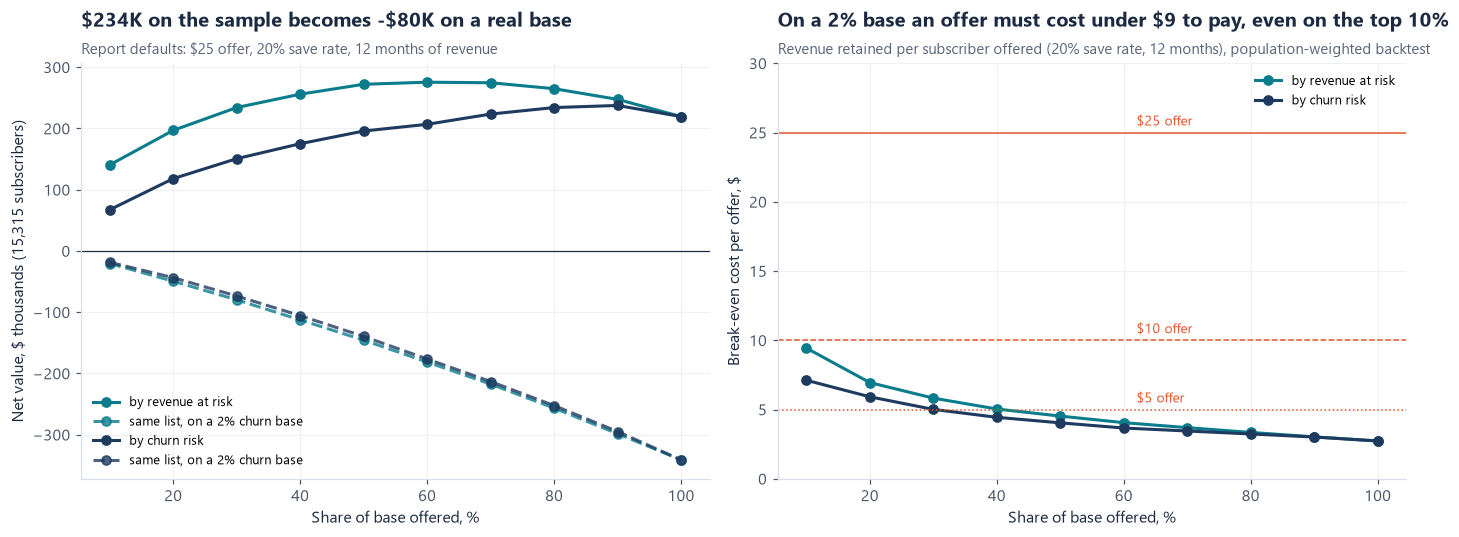

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
for r, c in (("value", PALETTE["teal"]), ("risk", PALETTE["navy"])):
    s_ = sim[sim["ranking"] == r]
    a1.plot(s_["share"], s_["net"] / 1e3, marker="o", color=c, label=f"by {'revenue at risk' if r == 'value' else 'churn risk'}")
    p_ = sim_pop[sim_pop["ranking"] == r]
    a1.plot(p_["share"], p_["net"] / 1e3, marker="o", ls="--", color=c, alpha=0.8, label="same list, on a 2% churn base")
    f_ = free[free["ranking"] == r]
    a2.plot(f_["share"], f_["break_even_cost"], marker="o", color=c, label=f"by {'revenue at risk' if r == 'value' else 'churn risk'}")
a1.axhline(0, color=PALETTE["ink"], lw=0.8)
a1.set_xlabel("Share of base offered, %"); a1.set_ylabel("Net value, $ thousands (15,315 subscribers)"); a1.legend(loc="lower left", fontsize=8.5)
headline(a1, f"${sv.loc[30, 'net'] / 1e3:,.0f}K on the sample becomes -${-pop.loc[30, 'net_value'] / 1e3:,.0f}K on a real base",
         "Report defaults: $25 offer, 20% save rate, 12 months of revenue")
for cost, ls in ((25, "-"), (10, "--"), (5, ":")):
    a2.axhline(cost, color=PALETTE["coral"], ls=ls, lw=1)
    a2.text(62, cost + 0.3, f"${cost} offer", color=PALETTE["coral"], fontsize=9, va="bottom")
a2.set_xlabel("Share of base offered, %"); a2.set_ylabel("Break-even cost per offer, $"); a2.legend(loc="upper right", fontsize=8.5)
a2.set_ylim(0, 30)
be10 = pop.loc[10, "break_even_cost_value"]
headline(a2, f"On a 2% base an offer must cost under ${be10:.0f} to pay, even on the top 10%",
         "Revenue retained per subscriber offered (20% save rate, 12 months), population-weighted backtest")
fig.tight_layout()
savefig(fig, "03-targeting", FIG); plt.show()

## 5. Offer only where the expected value is positive

Instead of whole deciles, use the prior-corrected probability (notebook 02) to compute each subscriber's EV and offer
only where it is positive. Backtested on the reweighted hold-out, against the EV the model expected:

In [8]:
p_pop = F.prior_correct(test["ChurnScore"].values)
rev_m = test["MonthlyRevenue"].fillna(0).values
yv = test["Churned"].values
ev_rows = []
for cost in (2.5, 5.0, 10.0, 25.0):
    ev = p_pop * 0.2 * 12 * rev_m - cost
    sel = ev > 0
    realised = np.sum(w * sel * yv * rev_m) * 0.2 * 12 - cost * np.sum(w * sel)
    ev_rows.append({"offer_cost": cost, "share_offered": sel.mean(), "subscribers_offered": int(sel.sum()), "expected_net": float(np.sum(w * sel * ev)),
                    "realised_net": realised, "min_monthly_revenue_offered": float(rev_m[sel].min()) if sel.any() else np.nan})
evt = pd.DataFrame(ev_rows).set_index("offer_cost")
evt

,share_offered,subscribers_offered,expected_net,realised_net,min_monthly_revenue_offered
offer_cost,,,,,
2.5000,0.4111,6296,"14,782.5587","14,500.5955",10.0000
5.0000,0.1476,2260,"6,463.0014","6,198.8350",18.8400
10.0000,0.0340,520,"1,909.1773","1,922.2665",34.9900
25.0000,0.0020,30,161.6189,424.0863,124.0300


Expected-value targeting picks the subscribers worth an offer at each price. At $5 it offers to 15% of the base (anyone
billing at least $19 a month with enough risk) and nets $6.2K on the reweighted hold-out, close to the $6.5K the model
expected. The agreement is the check that the prior correction works: probabilities rescaled to a 2% base predict the
realised value of the decision. At $10 only 3.4% of subscribers are worth an offer ($1.9K); at the report's $25 default,
0.2% ($0.4K). At $5 the EV rule also beats the best whole-decile policy (the top 10%, $5.8K), because it skips
low-revenue subscribers inside the top decile and picks up high-revenue ones outside it.

## 6. Sensitivity: which assumption decides the answer?

The candidate policy for a real base is the top 10% by revenue at risk with a cheap offer ($5, e.g. a data or bill
credit). Net value on the reweighted hold-out, moving one assumption at a time across a plausible range:

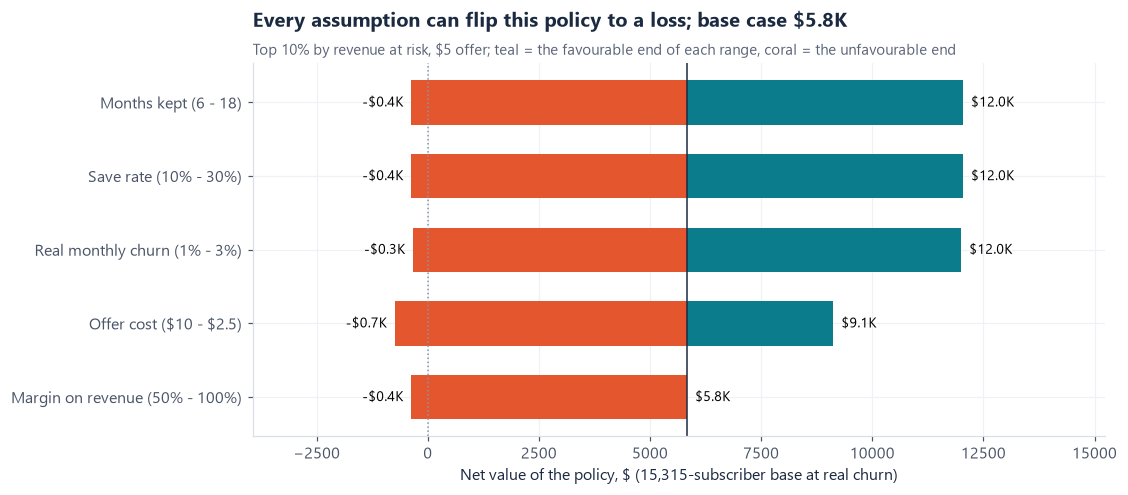

,low,high,swing
Margin on revenue (50% - 100%),-371.2742,"5,835.7287","6,207.0029"
Offer cost ($10 - $2.5),-742.5483,"9,124.8673","9,867.4156"
Real monthly churn (1% - 3%),-330.9415,"12,002.3990","12,333.3404"
Save rate (10% - 30%),-371.2742,"12,042.7317","12,414.0058"
Months kept (6 - 18),-371.2742,"12,042.7317","12,414.0058"


In [9]:
def policy_net(save=0.2, cost=5.0, months=12, margin=1.0, churn=0.02, share=10):
    ww = F.population_weights(yv, true_rate=churn)
    return F.simulate(test, "ValueDecile", share, offer_cost=cost, save_rate=save, months=months, margin=margin, weights=ww)["net"]


base = policy_net()
ranges = {"Save rate (10% - 30%)": ("save", 0.10, 0.30), "Offer cost ($10 - $2.5)": ("cost", 10.0, 2.5), "Months kept (6 - 18)": ("months", 6, 18),
          "Margin on revenue (50% - 100%)": ("margin", 0.5, 1.0), "Real monthly churn (1% - 3%)": ("churn", 0.01, 0.03)}
torn = pd.DataFrame({k: {"low": policy_net(**{p: lo}), "high": policy_net(**{p: hi})} for k, (p, lo, hi) in ranges.items()}).T
torn["swing"] = (torn["high"] - torn["low"]).abs()
torn = torn.sort_values("swing")
fig, ax = plt.subplots(figsize=(10, 4.4))
for i, (_k, r) in enumerate(torn.iterrows()):
    ax.barh(i, r["low"] - base, left=base, color=PALETTE["coral"], height=0.6)
    ax.barh(i, r["high"] - base, left=base, color=PALETTE["teal"], height=0.6)
    ax.text(min(r["low"], r["high"]), i, usd_k(min(r["low"], r["high"])) + "  ", ha="right", va="center", fontsize=9)
    ax.text(max(r["low"], r["high"]), i, "  " + usd_k(max(r["low"], r["high"])), ha="left", va="center", fontsize=9)
ax.axvline(base, color=PALETTE["ink"], lw=1)
ax.axvline(0, color=PALETTE["grey"], ls=":", lw=1)
ax.set_yticks(range(len(torn)), torn.index); ax.set_xlabel("Net value of the policy, $ (15,315-subscriber base at real churn)")
lo_, hi_ = torn[["low", "high"]].min().min(), torn[["low", "high"]].max().max()
ax.set_xlim(lo_ - (hi_ - lo_) * 0.25, hi_ + (hi_ - lo_) * 0.25)
headline(ax, f"Every assumption can flip this policy to a loss; base case ${base / 1e3:,.1f}K",
         "Top 10% by revenue at risk, $5 offer; teal = the favourable end of each range, coral = the unfavourable end")
savefig(fig, "03-tornado", FIG); plt.show()
torn

The base case (top 10% by revenue at risk, $5 offer, 20% save rate, 12 months, revenue as value, 2% churn) nets $5.8K per
15,315 subscribers. The low end of every single assumption turns it into a small loss: a 10% save rate, 6 months kept, a
1% churn rate, a 50% margin or a $10 offer. The upside is larger than the downside, which is why a small, measured test is
worth running and a large, unmeasured campaign is not.

## 7. Monte Carlo: all the uncertainty at once

2,000 draws. Each resamples the hold-out subscribers (sampling noise) and draws every assumption: save rate
~ Beta(4, 16) (mean 20%, 90% range 8%-35%), real churn ~ Uniform(1.5%, 2.5%), months kept ~ Uniform(6, 18) and margin
~ Uniform(50%, 100%). The ranked list is fixed, as it would be in production. Two offer costs.

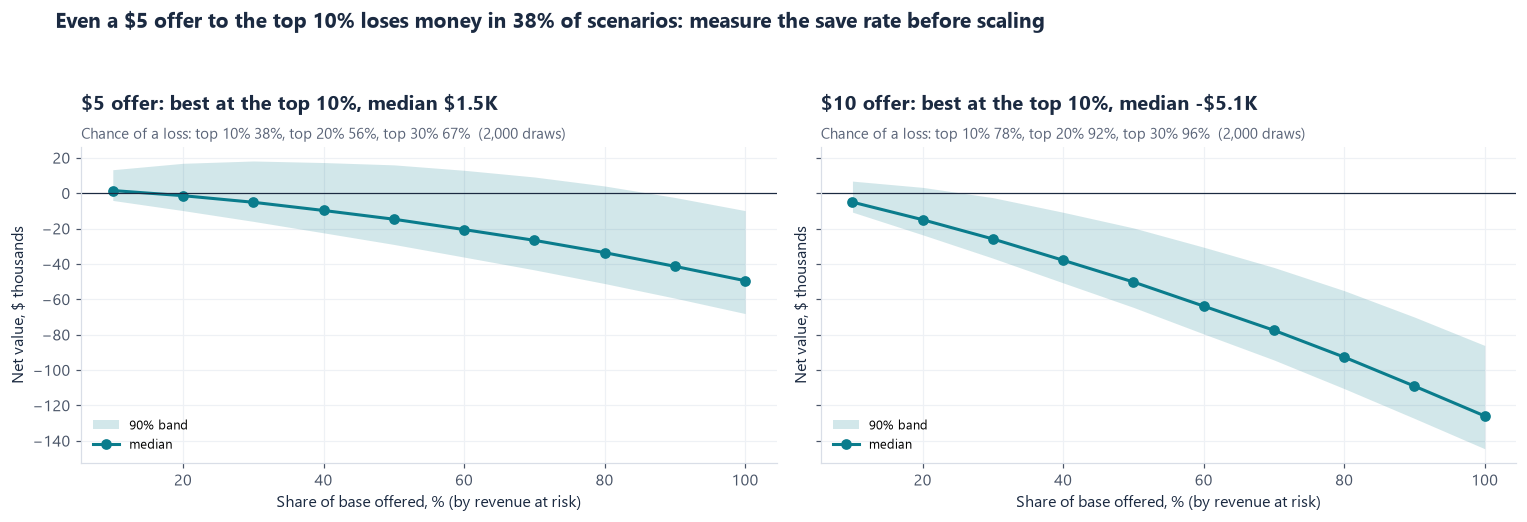

,$5 offer,$10 offer
top 10%,"1.5K (-4.1K to 13.3K), P(loss) 38%","-5.1K (-10.7K to 6.8K), P(loss) 78%"
top 20%,"-1.4K (-9.9K to 16.9K), P(loss) 56%","-15.0K (-23.6K to 3.3K), P(loss) 92%"
top 30%,"-5.2K (-15.9K to 18.2K), P(loss) 67%","-25.9K (-36.8K to -2.5K), P(loss) 96%"
top 40%,"-9.8K (-22.4K to 17.3K), P(loss) 74%","-38.0K (-50.7K to -10.8K), P(loss) 98%"
top 50%,"-14.7K (-29.0K to 16.0K), P(loss) 80%","-50.2K (-64.6K to -19.7K), P(loss) 99%"
top 60%,"-20.6K (-36.1K to 12.9K), P(loss) 86%","-63.9K (-79.6K to -30.5K), P(loss) 99%"
top 70%,"-26.7K (-43.4K to 9.1K), P(loss) 90%","-77.5K (-94.3K to -42.0K), P(loss) 100%"
top 80%,"-33.6K (-51.1K to 4.1K), P(loss) 93%","-92.7K (-110.5K to -55.1K), P(loss) 100%"
top 90%,"-41.4K (-59.3K to -2.4K), P(loss) 95%","-109.1K (-127.4K to -70.1K), P(loss) 100%"
top 100%,"-49.5K (-68.1K to -9.9K), P(loss) 97%","-126.0K (-144.5K to -86.1K), P(loss) 100%"


In [10]:
rng = np.random.default_rng(SEED)
dec_v = test["ValueDecile"].values
n_draw = 2000
mc = {c: np.zeros((n_draw, 10)) for c in (5.0, 10.0)}
for b in range(n_draw):
    ix = rng.integers(0, len(test), len(test))
    s_, ch, mo, mg = rng.beta(4, 16), rng.uniform(0.015, 0.025), rng.uniform(6, 18), rng.uniform(0.5, 1.0)
    ww = F.population_weights(yv[ix], true_rate=ch)
    gain = np.bincount(dec_v[ix], weights=ww * yv[ix] * rev_m[ix], minlength=11)[1:].cumsum() * s_ * mo * mg
    heads = np.bincount(dec_v[ix], weights=ww, minlength=11)[1:].cumsum()
    for c in mc:
        mc[c][b] = gain - c * heads
shares = np.arange(10, 101, 10)
mc_tab = pd.DataFrame({f"${c:.0f} offer": {f"top {s}%": f"{np.median(v[:, j]) / 1e3:,.1f}K ({np.percentile(v[:, j], 5) / 1e3:,.1f}K to "
                                                      f"{np.percentile(v[:, j], 95) / 1e3:,.1f}K), P(loss) {np.mean(v[:, j] < 0):.0%}"
                                           for j, s in enumerate(shares)} for c, v in mc.items()})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (c, v) in zip(axes, mc.items()):
    lo, med, hi = np.percentile(v, [5, 50, 95], axis=0) / 1e3
    ax.fill_between(shares, lo, hi, color=PALETTE["teal"], alpha=0.18, lw=0, label="90% band")
    ax.plot(shares, med, marker="o", color=PALETTE["teal"], label="median")
    ax.axhline(0, color=PALETTE["ink"], lw=0.8)
    ax.set_xlabel("Share of base offered, % (by revenue at risk)"); ax.set_ylabel("Net value, $ thousands")
    ax.legend(loc="lower left", fontsize=8.5)
    headline(ax, f"${c:.0f} offer: best at the top {shares[np.argmax(med)]}%, median {usd_k(med.max() * 1e3)}",
             "Chance of a loss: " + ", ".join(f"top {s_}% {np.mean(v[:, j] < 0):.0%}" for j, s_ in enumerate(shares[:3]))
             + "  (2,000 draws)")
fig.suptitle(f"Even a $5 offer to the top 10% loses money in {np.mean(mc[5.0][:, 0] < 0):.0%} of scenarios: measure the save rate before scaling",
             x=0.04, ha="left", fontsize=14,
             fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.93))
savefig(fig, "03-monte-carlo", FIG); plt.show()
mc_tab

With everything uncertain at once, the $5 offer to the top 10% has a median net of $1.5K and a 90% range from -$4.1K to
+$13.3K, a loss 38% of the time. Every larger share loses money in the median scenario. The $10 offer is worse at every
share. The dominant uncertainty is the save rate, and only an experiment can remove it.

## 8. The test that measures the save rate

The save rate drives every number above, and no data in this repo can estimate it: retention calls are observational
(notebook 01). Design: score the base monthly, take the top 10% by revenue at risk, randomise 80% to the offer and 20%
to a hold-out, and compare churn after 60 days. The primary metric is churn; guardrails are offer cost per save, ARPU
of saved subscribers and complaint rate. Sample size per arm for 80% power at 5% two-sided significance:

In [11]:
in_list = dec_v == 1
p0 = float(np.sum(w * in_list * yv) / np.sum(w * in_list))
rows = []
for save in (0.10, 0.20, 0.30):
    p1 = p0 * (1 - save)
    n = NormalIndPower().solve_power(proportion_effectsize(p0, p1), alpha=0.05, power=0.8, ratio=1.0)
    n_unbal = NormalIndPower().solve_power(proportion_effectsize(p0, p1), alpha=0.05, power=0.8, ratio=0.25)
    rows.append({"true_save_rate": save, "churn_without_offer": p0, "churn_with_offer": p1, "per_arm_50_50": int(np.ceil(n)),
                 "offer_arm_80_20": int(np.ceil(n_unbal)), "holdout_arm_80_20": int(np.ceil(n_unbal * 0.25))})
power = pd.DataFrame(rows).set_index("true_save_rate")
print(f"Real monthly churn in the top 10% by revenue at risk (reweighted hold-out): {p0:.2%} vs {F.ASSUMED_MONTHLY_CHURN:.0%} overall")
power

Real monthly churn in the top 10% by revenue at risk (reweighted hold-out): 3.20% vs 2% overall


,churn_without_offer,churn_with_offer,per_arm_50_50,offer_arm_80_20,holdout_arm_80_20
true_save_rate,,,,,
0.1000,0.0320,0.0288,45131,112826,28207
0.2000,0.0320,0.0256,10682,26703,6676
0.3000,0.0320,0.0224,4470,11175,2794


At a 3.2% monthly churn in the list, a 20% save rate means 0.64 points less churn. Detecting it with 80% power takes about
10,700 subscribers per arm at 50/50. A cheaper 80/20 design (fewer subscribers denied the offer) needs about 26,700
offered and 6,700 held out. A 10% save rate would need four times as many. For a carrier with a million subscribers, the
top 10% is 100,000 a month, so the test reads out within one or two monthly cycles.

## 9. Recommendation

1. **Keep the ranking: offer by revenue at risk, not by churn risk.** It is a property of the ranking, so it holds on any
   base: 58% of churned revenue in the top 30% vs 44%.
2. **Do not fund the default campaign on a real base.** $25 offers to the top 30% net $234K on the over-sampled hold-out
   but lose about $80K at a 2% monthly churn rate. The Power BI simulator would show this if it had a "real churn
   rate" input that applied the same prior correction. That is the one change I would make to the report.
3. **Price offers to the risk.** On a real base, even the top decile pays back only below about $9 per offer. Use small
   credits ($2.50-$5) and offer only where the prior-corrected expected value is positive. With a $5 offer that is about
   15% of the base, and about $40K per 100,000 subscribers per monthly campaign at the planning assumptions.
4. **Measure the save rate before scaling.** Randomise the top 10% by revenue at risk 80/20 into offer and hold-out, and
   read churn at 60 days. Detecting a 20% save rate (3.2% churn falling to 2.6%) needs about 10,700 subscribers per arm
   at 50/50, or about 26,700 offered and 6,700 held out at 80/20. For a carrier with 1M subscribers, that is one or two
   monthly lists.
5. **Leave the retention team's own callers out of the claims.** Subscribers who already called the retention team are
   in a separate process (notebook 01); counting their saves as model wins would double-count.

**Limitations.** The 2% monthly churn rate is an assumption; the tornado and the Monte Carlo vary it from 1% to 3%. Value
is revenue, not margin, as in the report; the Monte Carlo draws a 50-100% margin. A save is assumed to keep a subscriber
for the stated months with no offer cannibalisation (paying stayers who would never have left is counted as cost
only). The backtest is not causal; only the hold-out test is.

In [12]:
report.update_metrics(METRICS, "03_retention_economics", {
    "parity": {k: {"published": float(v["published"]), "reproduced": float(v["reproduced"])} for k, v in parity.iterrows()},
    "simulator_defaults_sample": {"net_30_value": float(sv.loc[30, "net"]), "roi_30_value": float(sv.loc[30, "roi"]), "best_share_value": int(sv["net"].idxmax()),
                                  "best_net_value": float(sv["net"].max()), "net_30_risk": float(sr.loc[30, "net"])},
    "simulator_defaults_real_base": {"net_30_value": float(pop.loc[30, "net_value"]), "net_30_risk": float(pop.loc[30, "net_risk"]),
                                     "break_even_cost_top10_value": float(be10)},
    "ev_targeting": {str(k): {kk: float(vv) for kk, vv in v.items()} for k, v in evt.iterrows()},
    "tornado_base_top10_5usd": float(base), "tornado": {k: {"low": float(v["low"]), "high": float(v["high"])} for k, v in torn.iterrows()},
    "monte_carlo": {f"{c:.0f}usd": {f"top{s}": {"median": float(np.median(v[:, j])), "p05": float(np.percentile(v[:, j], 5)),
                                               "p95": float(np.percentile(v[:, j], 95)), "p_loss": float(np.mean(v[:, j] < 0))} for j, s in enumerate(shares)}
                    for c, v in mc.items()},
    "ab_test": {"churn_top10_real": p0, "per_arm_at_20pct_save": int(power.loc[0.2, "per_arm_50_50"])},
})
print(f"metrics written; notebook runtime {time.perf_counter() - T0:.0f}s")

metrics written; notebook runtime 8s
